In [ ]:
!nvidia-smi | head -n 12
!pip -q install ultralytics torchinfo

Fri Oct  9 04:34:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/archive.zip"
DATA_DIR = "/content/data"

!rm -rf {DATA_DIR} && mkdir -p {DATA_DIR} && unzip -q "{ZIP_PATH}" -d {DATA_DIR}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, glob
n_dirs = 0
for root, dirs, files in os.walk(DATA_DIR):
    print(root, "->", len(files), "files")
    n_dirs += 1
    if n_dirs > 15: break

xml_files = glob.glob(DATA_DIR + "/**/*.xml", recursive=True)
print("\nXML files:", xml_files)
print(open(xml_files[0]).read()[:1500])

/content/data -> 2 files
/content/data/images -> 30 files
/content/data/boxes -> 30 files

XML files: ['/content/data/annotations.xml']
<?xml version="1.0" encoding="utf-8"?>
<annotations>
  <version>1.1</version>
  <meta>
    <task>
      <segments>
        <segment>
          <id>32599</id>
          <start>0</start>
          <stop>32</stop>
          <url>https://cvat2.trainingdata.solutions/api/jobs/32599</url>
        </segment>
      </segments>
      <owner>
        <username>TrainingData</username>
        <email/>
      </owner>
      
      <labels>
        <label>
          <name>free_parking_space</name>
          <color>#3d3df5</color>
          <type>polygon</type>
          <attributes>
            <attribute>
              <name>not_visible</name>
              <mutable>False</mutable>
              <input_type>checkbox</input_type>
              <default_value>false</default_value>
              <values>false</values>
            </attribute>
          </attributes>
 

In [ ]:
import xml.etree.ElementTree as ET
import pandas as pd

SEED = 42
PARTIAL = "occupied"

XML_PATH = xml_files[0]


img_index = {os.path.basename(p): p
             for p in glob.glob(DATA_DIR + "/**/*", recursive=True)
             if p.lower().endswith((".jpg", ".jpeg", ".png")) and "boxes" not in p.lower().split(os.sep)}
print("clean images found:", len(img_index))

def map_label(l):
    l = l.lower()
    if "partial" in l:  return 1 if PARTIAL == "occupied" else None
    if "not_free" in l: return 1
    if "free" in l:     return 0
    return None

rows = []
root = ET.parse(XML_PATH).getroot()
for im in root.iter("image"):
    name = os.path.basename(im.get("name"))
    if name not in img_index:
        continue
    img_path = img_index[name]
    W, H = int(float(im.get("width"))), int(float(im.get("height")))
    for b in im.findall("box"):
        rows.append(dict(image=name, path=img_path, W=W, H=H, label=b.get("label"),
                         x1=float(b.get("xtl")), y1=float(b.get("ytl")),
                         x2=float(b.get("xbr")), y2=float(b.get("ybr"))))
    for p in im.findall("polygon"):
        pts = [tuple(map(float, q.split(","))) for q in p.get("points").split(";")]
        xs, ys = zip(*pts)
        rows.append(dict(image=name, path=img_path, W=W, H=H, label=p.get("label"),
                         x1=min(xs), y1=min(ys), x2=max(xs), y2=max(ys)))

df = pd.DataFrame(rows)
assert len(df) > 0, "No boxes parsed - check the XML structure printed in Step 2"
df["y"] = df["label"].map(map_label)
df = df.dropna(subset=["y"]).copy()
df["y"] = df["y"].astype(int)

print("Images:", df.image.nunique(), "| Slot boxes:", len(df))
print(df.label.value_counts())
print("\nSlots per image:\n", df.groupby("image").size().describe())

clean images found: 30
Images: 30 | Slot boxes: 903
label
not_free_parking_space          624
free_parking_space              273
partially_free_parking_space      6
Name: count, dtype: int64

Slots per image:
 count    30.000000
mean     30.100000
std      15.788145
min       6.000000
25%      22.000000
50%      26.000000
75%      36.000000
max      81.000000
dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

imgs = df.image.unique()
tr, tmp = train_test_split(imgs, test_size=0.30, random_state=SEED)
va, te  = train_test_split(tmp,  test_size=0.50, random_state=SEED)
split_of = {**{i: "train" for i in tr}, **{i: "val" for i in va}, **{i: "test" for i in te}}
df["split"] = df.image.map(split_of)

print(df.groupby(["split", "y"]).size().unstack(fill_value=0).rename(columns={0: "vacant", 1: "occupied"}))
print(df.groupby("split").image.nunique().rename("images"))

y      vacant  occupied
split                  
test       68       126
train     164       422
val        41        82
split
test      5
train    21
val       4
Name: images, dtype: int64


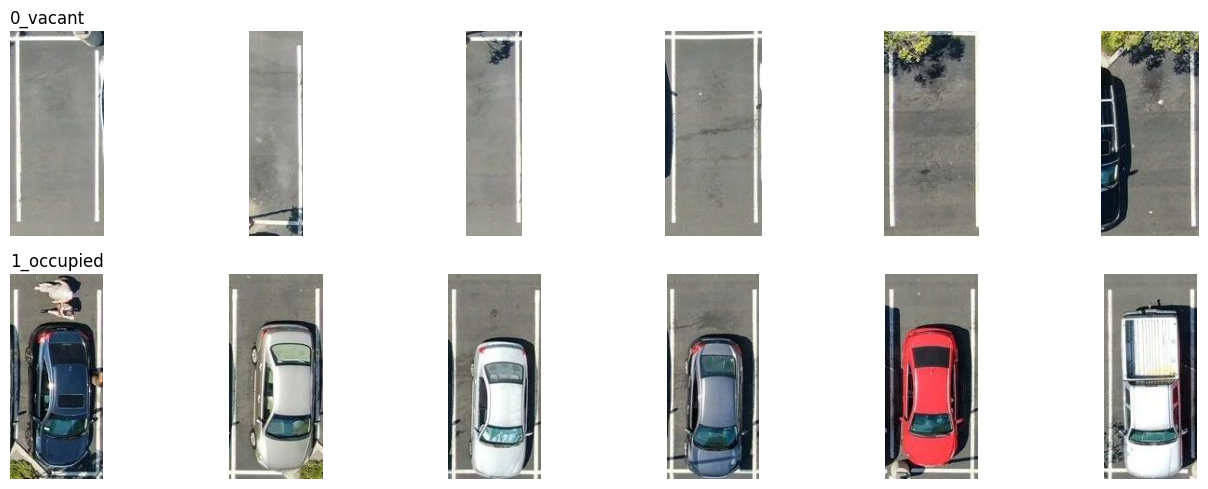

In [ ]:
import shutil
from PIL import Image

CROP_DIR, PAD = "/content/crops", 0.08
shutil.rmtree(CROP_DIR, ignore_errors=True)
cls_name = {0: "0_vacant", 1: "1_occupied"}

for name, g in df.groupby("image"):
    im = Image.open(g.path.iloc[0]).convert("RGB")
    for idx, r in g.iterrows():
        w, h = r.x2 - r.x1, r.y2 - r.y1
        box = (max(0, r.x1 - PAD*w), max(0, r.y1 - PAD*h), min(r.W, r.x2 + PAD*w), min(r.H, r.y2 + PAD*h))
        out = f"{CROP_DIR}/{r.split}/{cls_name[r.y]}"
        os.makedirs(out, exist_ok=True)
        im.crop(tuple(int(v) for v in box)).save(f"{out}/{os.path.splitext(name)[0]}_{idx}.jpg")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for row, c in enumerate(cls_name.values()):
    files = sorted(glob.glob(f"{CROP_DIR}/train/{c}/*.jpg"))[:6]
    for col, f in enumerate(files):
        ax[row, col].imshow(Image.open(f)); ax[row, col].axis("off")
    ax[row, 0].set_title(c, loc="left")
plt.tight_layout(); plt.savefig("/content/fig_samples.png", dpi=150); plt.show()

In [ ]:
import torch, torch.nn as nn, numpy as np, time
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

IMNET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def make_loaders(size, bs=32, mean_std=((0.5,)*3, (0.5,)*3)):
    norm = transforms.Normalize(*mean_std)
    t_train = transforms.Compose([transforms.Resize((size, size)),
        transforms.RandomHorizontalFlip(), transforms.RandomRotation(5),
        transforms.ColorJitter(0.3, 0.3, 0.3), transforms.ToTensor(), norm])
    t_eval = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(), norm])
    ds = {s: datasets.ImageFolder(f"{CROP_DIR}/{s}", t_train if s == "train" else t_eval)
          for s in ["train", "val", "test"]}
    dl = {s: DataLoader(ds[s], batch_size=bs, shuffle=(s == "train"), num_workers=2) for s in ds}
    return ds, dl

ds64, dl64   = make_loaders(64)
ds224, dl224 = make_loaders(224, bs=32, mean_std=IMNET)
print(ds64["train"].class_to_idx)

targets = np.array(ds64["train"].targets)
pos_weight = torch.tensor([(targets == 0).sum() / max(1, (targets == 1).sum())], dtype=torch.float32).to(device)
print("pos_weight (vacant/occupied):", pos_weight.item())

device: cuda
{'0_vacant': 0, '1_occupied': 1}
pos_weight (vacant/occupied): 0.3886255919933319


In [ ]:
from torchinfo import summary

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128*8*8, 128), nn.ReLU(),
                                  nn.Dropout(0.5), nn.Linear(128, 1))
    def forward(self, x): return self.head(self.features(x))

class MAlexNetStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 20, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(20, 30, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(30*8*8, 48), nn.ReLU(),
                                  nn.Dropout(0.5), nn.Linear(48, 1))
    def forward(self, x): return self.head(self.features(x))

def make_mobilenet():
    m = models.mobilenet_v2(weights="DEFAULT")
    m.classifier[1] = nn.Linear(m.last_channel, 1)
    return m

def n_params(m): return sum(p.numel() for p in m.parameters())
summary(CustomCNN(), input_size=(1, 3, 64, 64))
print("mAlexNet-style params:", n_params(MAlexNetStyle()), "| MobileNetV2 params:", n_params(make_mobilenet()))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 144MB/s]

mAlexNet-style params: 106923 | MobileNetV2 params: 2225153


In [ ]:
import copy

def run_epoch(model, loader, crit, opt=None):
    train = opt is not None
    model.train(train)
    tot_loss = tot_ok = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.float().to(device)
            logit = model(x).squeeze(1)
            loss = crit(logit, y)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            tot_ok += ((logit > 0).float() == y).sum().item()
            n += len(y)
    return tot_loss / n, tot_ok / n

def fit(model, dl, epochs, lr, patience=7, name="model"):
    model.to(device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
    best, best_state, bad = 1e9, None, 0
    t0 = time.time()
    for ep in range(epochs):
        trl, tra = run_epoch(model, dl["train"], crit, opt)
        vl, va = run_epoch(model, dl["val"], crit)
        for k, v in zip(hist, (trl, vl, tra, va)): hist[k].append(v)
        print(f"{name} ep{ep+1:02d} train {trl:.3f}/{tra:.3f}  val {vl:.3f}/{va:.3f}")
        if vl < best: best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: print("early stop"); break
    model.load_state_dict(best_state)
    hist["train_time_s"] = time.time() - t0
    return hist

In [ ]:
H = {}
m_cnn = CustomCNN();      H["Custom CNN"]  = fit(m_cnn, dl64, epochs=40, lr=1e-3, name="cnn")
m_mal = MAlexNetStyle();  H["mAlexNet-style"] = fit(m_mal, dl64, epochs=40, lr=1e-3, name="malex")

m_mob = make_mobilenet().to(device)
for p in m_mob.features.parameters(): p.requires_grad = False
h1 = fit(m_mob, dl224, epochs=5, lr=1e-3, patience=5, name="mob-head")
for p in m_mob.features[14:].parameters(): p.requires_grad = True
h2 = fit(m_mob, dl224, epochs=12, lr=1e-4, patience=5, name="mob-ft")
H["MobileNetV2"] = {k: (h1[k] + h2[k] if k != "train_time_s" else h1[k] + h2[k]) for k in h1}

cnn ep01 train 0.284/0.795  val 0.294/0.675
cnn ep02 train 0.121/0.913  val 0.284/0.911
cnn ep03 train 0.092/0.951  val 0.088/0.911
cnn ep04 train 0.080/0.949  val 0.096/0.951
cnn ep05 train 0.057/0.973  val 0.081/0.943
cnn ep06 train 0.071/0.964  val 0.168/0.935
cnn ep07 train 0.074/0.957  val 0.128/0.870
cnn ep08 train 0.066/0.961  val 0.147/0.935
cnn ep09 train 0.065/0.962  val 0.077/0.967
cnn ep10 train 0.070/0.966  val 0.098/0.911
cnn ep11 train 0.045/0.969  val 0.138/0.935
cnn ep12 train 0.062/0.968  val 0.080/0.959
cnn ep13 train 0.039/0.974  val 0.067/0.959
cnn ep14 train 0.041/0.973  val 0.088/0.967
cnn ep15 train 0.038/0.978  val 0.056/0.959
cnn ep16 train 0.038/0.973  val 0.069/0.976
cnn ep17 train 0.038/0.974  val 0.055/0.984
cnn ep18 train 0.051/0.964  val 0.040/0.984
cnn ep19 train 0.055/0.956  val 0.096/0.894
cnn ep20 train 0.047/0.961  val 0.091/0.943
cnn ep21 train 0.036/0.978  val 0.053/0.951
cnn ep22 train 0.026/0.985  val 0.083/0.976
cnn ep23 train 0.032/0.978  val 

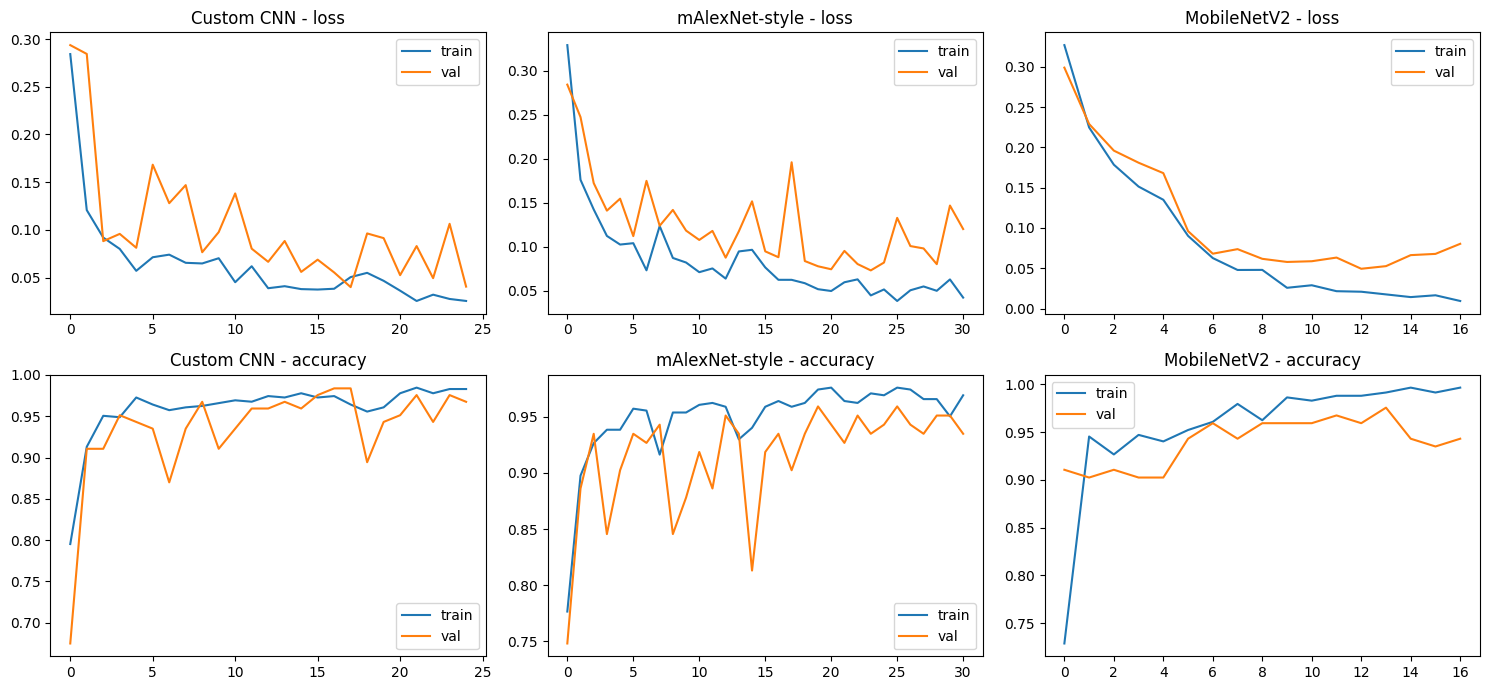

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, (name, h) in enumerate(H.items()):
    ax[0, j].plot(h["train_loss"], label="train"); ax[0, j].plot(h["val_loss"], label="val")
    ax[0, j].set_title(name + " - loss"); ax[0, j].legend()
    ax[1, j].plot(h["train_acc"], label="train"); ax[1, j].plot(h["val_acc"], label="val")
    ax[1, j].set_title(name + " - accuracy"); ax[1, j].legend()
plt.tight_layout(); plt.savefig("/content/fig_training.png", dpi=150); plt.show()

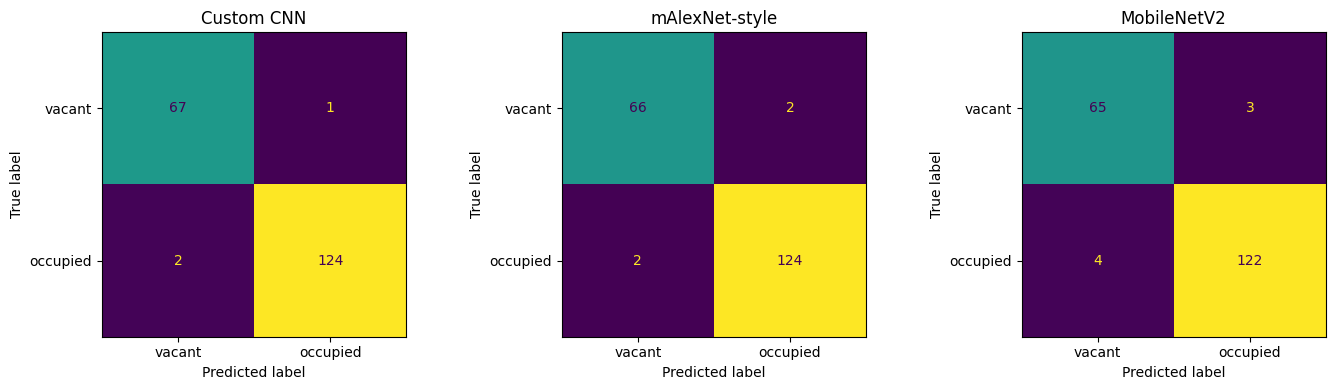

,Model,Accuracy,Precision,Recall,F1,Params,ms_per_image,Train_time_s
0,Custom CNN,0.9845,0.9920,0.9841,0.9880,1142081,1.0678,28.2994
1,mAlexNet-style,0.9794,0.9841,0.9841,0.9841,106923,1.0539,34.0535
2,MobileNetV2,0.9639,0.9760,0.9683,0.9721,2225153,2.7590,55.1138


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P += torch.sigmoid(model(x.to(device)).squeeze(1)).cpu().tolist(); Y += y.tolist()
    return np.array(P), np.array(Y)

@torch.no_grad()
def ms_per_image(model, loader):
    model.eval(); n = 0
    x0, _ = next(iter(loader)); model(x0.to(device))
    if device == "cuda": torch.cuda.synchronize()
    t = time.time()
    for x, _ in loader: model(x.to(device)); n += len(x)
    if device == "cuda": torch.cuda.synchronize()
    return 1000 * (time.time() - t) / n

def metric_row(name, y, pred, params, ms, train_s):
    return dict(Model=name, Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred, zero_division=0), F1=f1_score(y, pred, zero_division=0),
                Params=params, ms_per_image=ms, Train_time_s=train_s)

rows, CM = [], {}
for name, m, dl in [("Custom CNN", m_cnn, dl64), ("mAlexNet-style", m_mal, dl64), ("MobileNetV2", m_mob, dl224)]:
    p, y = predict(m, dl["test"]); pred = (p > 0.5).astype(int)
    rows.append(metric_row(name, y, pred, n_params(m), ms_per_image(m, dl["test"]), H[name]["train_time_s"]))
    CM[name] = confusion_matrix(y, pred)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, cm) in zip(ax, CM.items()):
    ConfusionMatrixDisplay(cm, display_labels=["vacant", "occupied"]).plot(ax=a, colorbar=False); a.set_title(name)
plt.tight_layout(); plt.savefig("/content/fig_confusion.png", dpi=150); plt.show()
pd.DataFrame(rows).round(4)

In [ ]:
YOLO_DIR = "/content/yolo"
shutil.rmtree(YOLO_DIR, ignore_errors=True)
for s in ["train", "val", "test"]:
    os.makedirs(f"{YOLO_DIR}/images/{s}", exist_ok=True); os.makedirs(f"{YOLO_DIR}/labels/{s}", exist_ok=True)

for name, g in df.groupby("image"):
    s = g.split.iloc[0]
    shutil.copy(g.path.iloc[0], f"{YOLO_DIR}/images/{s}/{name}")
    with open(f"{YOLO_DIR}/labels/{s}/{os.path.splitext(name)[0]}.txt", "w") as f:
        for _, r in g.iterrows():
            xc, yc = (r.x1 + r.x2) / 2 / r.W, (r.y1 + r.y2) / 2 / r.H
            f.write(f"{int(r.y)} {xc:.6f} {yc:.6f} {(r.x2 - r.x1)/r.W:.6f} {(r.y2 - r.y1)/r.H:.6f}\n")

with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: vacant\n  1: occupied\n")

from ultralytics import YOLO
yolo = YOLO("yolov8n.pt")
t0 = time.time()
yolo.train(data=f"{YOLO_DIR}/data.yaml", epochs=60, imgsz=640, batch=8, patience=15,
           project="/content/runs", name="parking", seed=SEED, verbose=False)
yolo_train_s = time.time() - t0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

In [ ]:
best = YOLO("/content/runs/parking/weights/best.pt")

def iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

y_true, y_pred, missed, total = [], [], 0, 0
t0 = time.time(); n_img = 0
for name, g in df[df.split == "test"].groupby("image"):
    r = best.predict(g.path.iloc[0], conf=0.25, verbose=False)[0]; n_img += 1
    pb = r.boxes.xyxy.cpu().numpy(); pc = r.boxes.cls.cpu().numpy().astype(int)
    for _, s in g.iterrows():
        total += 1
        ious = [iou((s.x1, s.y1, s.x2, s.y2), b) for b in pb]
        if len(ious) and max(ious) >= 0.5:
            y_true.append(int(s.y)); y_pred.append(int(pc[int(np.argmax(ious))]))
        else:
            missed += 1
ms_yolo = 1000 * (time.time() - t0) / max(1, n_img)

print(f"slots in test images: {total} | detected (IoU>=0.5): {total-missed} | missed: {missed}")
yolo_row = metric_row("YOLOv8n (matched slots)", y_true, y_pred, n_params(best.model), ms_yolo, yolo_train_s)
yolo_row["Detection_recall"] = (total - missed) / total
cm_y = confusion_matrix(y_true, y_pred); print(cm_y)

slots in test images: 194 | detected (IoU>=0.5): 132 | missed: 62
[[ 23   5]
 [  0 104]]


In [ ]:
final = pd.DataFrame(rows + [yolo_row]).round(4)
final.to_csv("/content/final_results.csv", index=False)
final

,Model,Accuracy,Precision,Recall,F1,Params,ms_per_image,Train_time_s,Detection_recall
0,Custom CNN,0.9845,0.9920,0.9841,0.9880,1142081,1.0678,28.2994,NaN
1,mAlexNet-style,0.9794,0.9841,0.9841,0.9841,106923,1.0539,34.0535,NaN
2,MobileNetV2,0.9639,0.9760,0.9683,0.9721,2225153,2.7590,55.1138,NaN
3,YOLOv8n (matched slots),0.9621,0.9541,1.0000,0.9765,3011238,113.5861,60.6752,0.6804


18.png errors 0/25


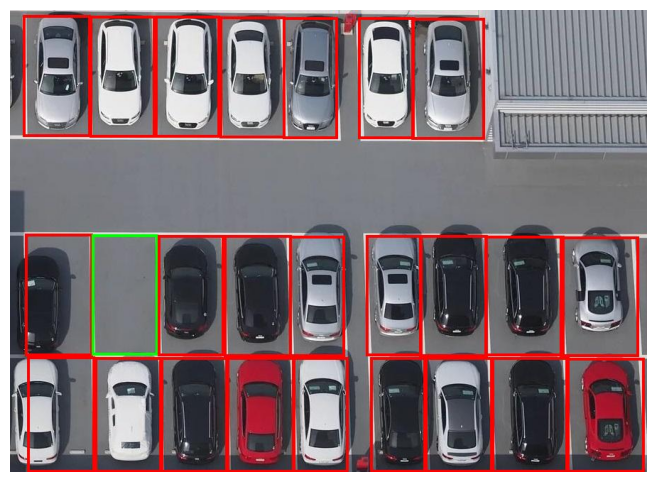

20.png errors 0/26


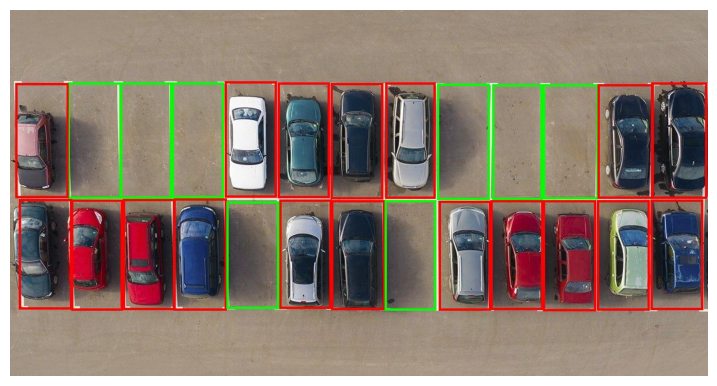

24.png errors 0/26


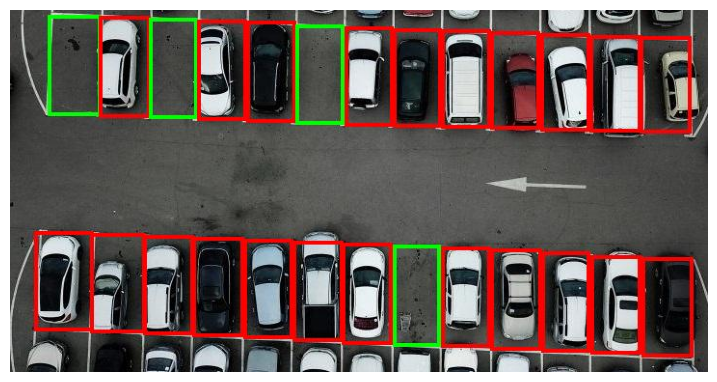

In [ ]:
from PIL import ImageDraw

@torch.no_grad()
def draw_classifier(model, size, mean_std, image_name, out):
    g = df[df.image == image_name]; im = Image.open(g.path.iloc[0]).convert("RGB"); d = ImageDraw.Draw(im)
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(), transforms.Normalize(*mean_std)])
    model.eval(); wrong = 0
    for _, r in g.iterrows():
        crop = im.crop((int(r.x1), int(r.y1), int(r.x2), int(r.y2)))
        p = torch.sigmoid(model(tf(crop).unsqueeze(0).to(device))).item()
        occ = p > 0.5; wrong += int(occ != bool(r.y))
        d.rectangle([r.x1, r.y1, r.x2, r.y2], outline="red" if occ else "lime", width=4)
    im.save(out); return wrong, len(g)

test_imgs = df[df.split == "test"].image.unique()
for k, nm in enumerate(test_imgs[:3]):
    w, n = draw_classifier(m_mob, 224, IMNET, nm, f"/content/pred_{k}.jpg")
    print(nm, f"errors {w}/{n}")
    plt.figure(figsize=(9, 6)); plt.imshow(Image.open(f"/content/pred_{k}.jpg")); plt.axis("off"); plt.show()

In [ ]:
OUT = "/content/drive/MyDrive/parking_results"
os.makedirs(OUT, exist_ok=True)
for f in ["fig_samples.png", "fig_training.png", "fig_confusion.png", "final_results.csv", "pred_0.jpg", "pred_1.jpg", "pred_2.jpg"]:
    if os.path.exists("/content/" + f): shutil.copy("/content/" + f, OUT)
!cp -r /content/runs/parking {OUT}/yolo_run
torch.save(m_cnn.state_dict(), OUT + "/custom_cnn.pt"); torch.save(m_mal.state_dict(), OUT + "/malexnet_style.pt")
torch.save(m_mob.state_dict(), OUT + "/mobilenetv2.pt")
print("saved to", OUT)

saved to /content/drive/MyDrive/parking_results


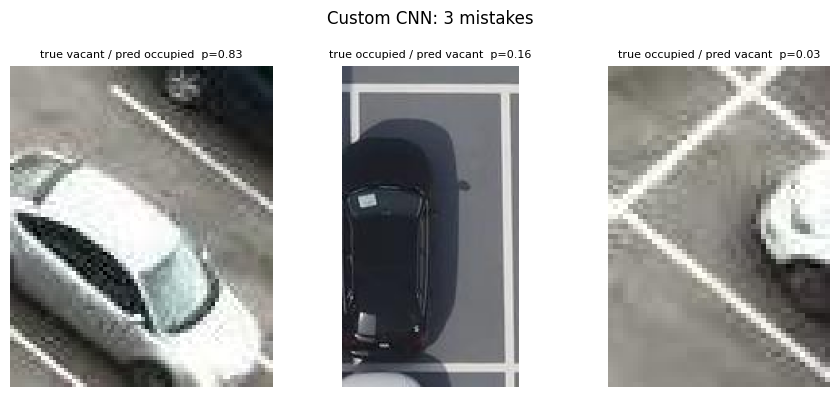

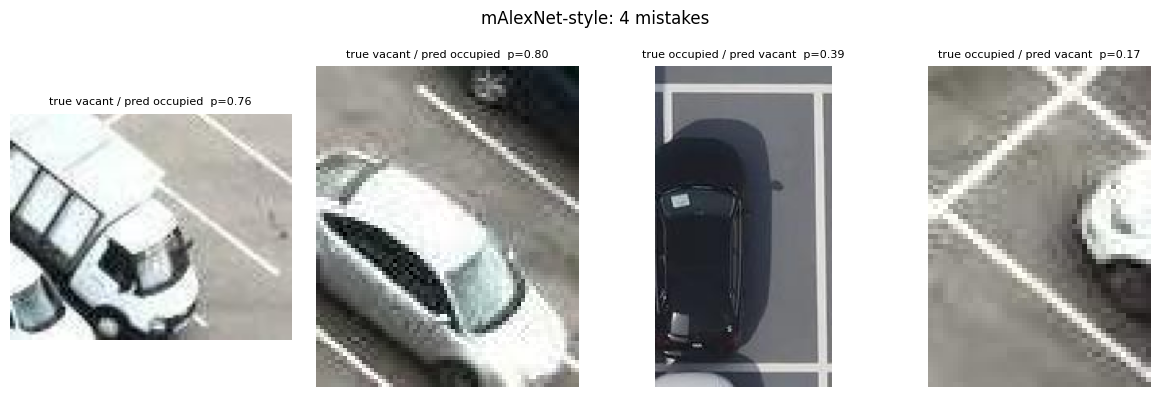

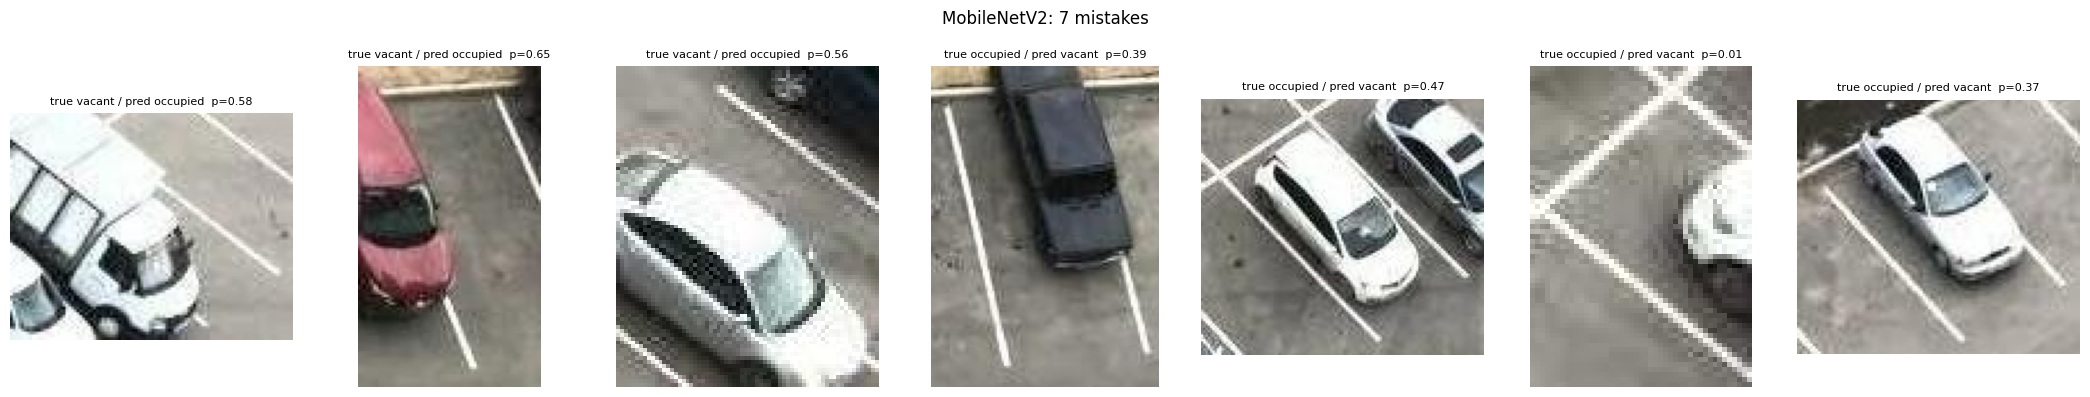

In [ ]:
for name, m, dl, ds in [("Custom CNN", m_cnn, dl64, ds64), ("mAlexNet-style", m_mal, dl64, ds64), ("MobileNetV2", m_mob, dl224, ds224)]:
    p, y = predict(m, dl["test"]); pred = (p > 0.5).astype(int)
    paths = [s[0] for s in ds["test"].samples]
    bad = [i for i in range(len(y)) if pred[i] != y[i]]
    fig, ax = plt.subplots(1, max(2, len(bad)), figsize=(3 * max(2, len(bad)), 4))
    for a in np.atleast_1d(ax): a.axis("off")
    for a, i in zip(np.atleast_1d(ax), bad):
        a.imshow(Image.open(paths[i]))
        a.set_title(f"true {'occupied' if y[i] else 'vacant'} / pred {'occupied' if pred[i] else 'vacant'}  p={p[i]:.2f}", fontsize=8)
    fig.suptitle(f"{name}: {len(bad)} mistakes"); plt.tight_layout(); plt.show()